# Demo 12 - Case de fechamento: previsão de churn em telecom, modelos clássicos x rede neural

### MBA em AI Engineering & Multi Agents - Machine Learning Foundations & Classic Models.

### Prof. Dr. Ahirton Lopes (profahirton.lopes@fiap.com.br)

Ref. - IBM, *Telco Customer Churn* (licença Apache 2.0): https://github.com/IBM/telco-customer-churn-on-icp4d

## Objetivo da demo

Esta é a demo de fechamento da disciplina. Vamos juntar **tudo o que vimos nas quatro aulas** em um único problema de negócio:

> **Uma operadora de telecom quer saber quais clientes têm maior risco de cancelar o contrato (churn), para direcionar uma campanha de retenção. Qual modelo usar, e como decidir quem recebe a oferta?**

| Seção | Conteúdo | Onde vimos |
| --- | --- | --- |
| 1-2 | Carregar e conhecer os dados, incluindo um problema de qualidade escondido | Aula 1 |
| 3 | Preparação: variáveis categóricas, escala e divisão treino/teste estratificada | Aulas 1 e 2 |
| 4 | Baseline: o modelo "burro" que todo modelo precisa vencer | Aula 1 (Demos 1 e 2) |
| 5 | Torneio: regressão logística, árvore, Random Forest, Gradient Boosting e **MLP** | Aulas 1, 2 e 4 |
| 6 | Curvas ROC e a escolha da métrica certa | Aula 1 (Demo 3) |
| 7 | Do modelo à decisão: o limiar que maximiza o resultado da campanha | Aula 1 (Demo 2, ato 3) |
| 8 | Interpretabilidade: o que o modelo aprendeu | Aula 2 |
| 9 | Conclusão: quando usar ML clássico e quando usar redes neurais | Aula 4 |

## 1. Importando bibliotecas

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore')
SEMENTE = 42

## 2. Carregando e conhecendo os dados

In [2]:
# Baixando a base de dados direto do repositório da disciplina para o Google Colab
# Fonte original: https://github.com/IBM/telco-customer-churn-on-icp4d (licença Apache 2.0)

!curl -O https://raw.githubusercontent.com/ahirtonlopes/Machine-Learning-Foundations-and-Classic-Models/main/Datasets/Telco-Customer-Churn.csv

In [3]:
# ALTERNATIVA: se preferir subir o arquivo na mão, descomente as linhas abaixo,
# execute esta célula e selecione o Telco-Customer-Churn.csv do seu computador.

# from google.colab import files
#
# uploaded = files.upload()
#
# for fn in uploaded.keys():
#     print('Arquivo "{name}" com {length} bytes'.format(
#         name=fn, length=len(uploaded[fn])))

In [4]:
clientes = pd.read_csv('Telco-Customer-Churn.csv')

print('Formato (linhas, colunas):', clientes.shape)
clientes.head()

Formato (linhas, colunas): (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Cada linha é um cliente. As colunas descrevem:

| Grupo | Colunas |
| --- | --- |
| Perfil | `gender`, `SeniorCitizen`, `Partner`, `Dependents` |
| Relacionamento | `tenure` (meses como cliente), `Contract` (mensal, 1 ano, 2 anos), `PaperlessBilling`, `PaymentMethod` |
| Serviços | `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `TechSupport`, `StreamingTV` etc. |
| Financeiro | `MonthlyCharges` (mensalidade), `TotalCharges` (total já pago) |
| **Alvo** | `Churn`: o cliente cancelou no último mês? (`Yes`/`No`) |

### Pergunta de sempre (Aula 1): a base é balanceada?

Clientes que cancelaram: 26.5%
Clientes que ficaram   : 73.5%


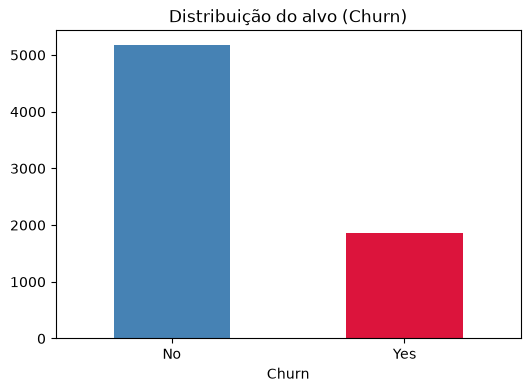

In [5]:
taxa_churn = (clientes['Churn'] == 'Yes').mean()
print(f'Clientes que cancelaram: {taxa_churn:.1%}')
print(f'Clientes que ficaram   : {1 - taxa_churn:.1%}')

clientes['Churn'].value_counts().plot(kind='bar', color=['steelblue', 'crimson'], figsize=(6, 4),
                                       title='Distribuição do alvo (Churn)')
plt.xticks(rotation=0)
plt.show()

Cerca de **1 em cada 4** clientes cancelou. Não é o desbalanceamento extremo da fraude (Demo 2), mas já é suficiente para a acurácia enganar: um modelo que diga "ninguém vai cancelar" acerta ~73%.

### Um problema de qualidade escondido

Olhe o tipo de cada coluna. `TotalCharges` deveria ser número, mas veio como texto (`object`).

In [6]:
print(clientes[['tenure', 'MonthlyCharges', 'TotalCharges']].dtypes)

total_numerico = pd.to_numeric(clientes['TotalCharges'], errors='coerce')
problemas = clientes[total_numerico.isna()]
print(f'\nLinhas em que TotalCharges não é número: {len(problemas)}')
problemas[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

tenure              int64
MonthlyCharges    float64
TotalCharges          str
dtype: object

Linhas em que TotalCharges não é número: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


São clientes com `tenure = 0`: acabaram de entrar e **ainda não pagaram nada**, então o campo veio em branco (um espaço). Não é dado faltante aleatório, é uma regra de negócio. A correção coerente é preencher com **0**, e não com a média.

Esse é o tipo de detalhe que nenhum modelo, clássico ou neural, resolve sozinho.

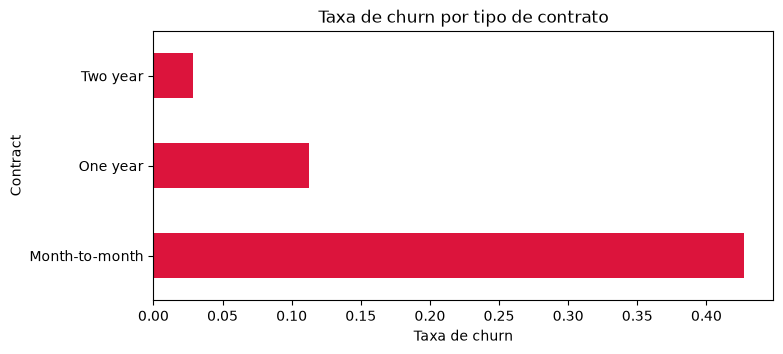

In [7]:
clientes['TotalCharges'] = pd.to_numeric(clientes['TotalCharges'], errors='coerce').fillna(0)

# Churn por tipo de contrato: a primeira pista de negócio
(clientes.groupby('Contract')['Churn']
         .apply(lambda s: (s == 'Yes').mean())
         .sort_values(ascending=False)
         .plot(kind='barh', color='crimson', figsize=(8, 3.5), title='Taxa de churn por tipo de contrato'))
plt.xlabel('Taxa de churn')
plt.show()

Clientes com **contrato mensal** cancelam muito mais do que os de contratos de 1 ou 2 anos. Guarde essa observação: vamos ver se os modelos chegam à mesma conclusão na seção 8.

## 3. Preparando os dados

- `customerID` é só um identificador, sai do modelo;
- o alvo vira 0/1;
- variáveis **categóricas** viram colunas binárias (*one-hot encoding*);
- variáveis **numéricas** são padronizadas (média 0, desvio 1). Isso é **obrigatório** para a regressão logística e para o MLP, que usam descida do gradiente (Demo 10): variáveis em escalas muito diferentes deixam a "montanha" torta e o treino lento. Para as árvores é indiferente;
- divisão **estratificada** 80/20, para manter a mesma proporção de churn no treino e no teste.

In [8]:
y = (clientes['Churn'] == 'Yes').astype(int)
X = clientes.drop(columns=['customerID', 'Churn'])

numericas = ['tenure', 'MonthlyCharges', 'TotalCharges']
categoricas = [c for c in X.columns if c not in numericas]

preprocessamento = ColumnTransformer([
    ('num', StandardScaler(), numericas),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categoricas),
])

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=SEMENTE, stratify=y)

print(f'Treino: {X_treino.shape[0]} clientes | Teste: {X_teste.shape[0]} clientes')
print(f'Churn no treino: {y_treino.mean():.1%} | no teste: {y_teste.mean():.1%}')
print(f'Variáveis depois do one-hot: {preprocessamento.fit(X_treino).transform(X_treino).shape[1]}')

Treino: 5634 clientes | Teste: 1409 clientes
Churn no treino: 26.5% | no teste: 26.5%
Variáveis depois do one-hot: 46


## 4. O baseline

Lição da Aula 1: **antes de comemorar qualquer métrica, compare com o modelo mais burro possível**. O `DummyClassifier` sempre responde a classe mais frequente ("não vai cancelar").

In [9]:
baseline = DummyClassifier(strategy='most_frequent').fit(X_treino, y_treino)
pred_base = baseline.predict(X_teste)

print(f'Baseline -> acurácia: {accuracy_score(y_teste, pred_base):.3f}')
print(f'Baseline -> recall  : {recall_score(y_teste, pred_base):.3f}  (não encontra NENHUM cliente que vai cancelar)')

Baseline -> acurácia: 0.735
Baseline -> recall  : 0.000  (não encontra NENHUM cliente que vai cancelar)


**73% de acurácia sem aprender nada.** Qualquer modelo que não passe com folga desse número, ou que tenha recall perto de zero, não serve para a campanha.

## 5. O torneio: cinco modelos, as mesmas regras

Todos os modelos recebem **o mesmo pré-processamento**, a **mesma divisão** e são avaliados pelas **mesmas métricas**:

| Modelo | Família | Onde vimos |
| --- | --- | --- |
| Regressão logística | Linear | Aula 1 |
| Árvore de decisão | Árvore | Aula 2 |
| Random Forest | Ensemble (bagging) | Aula 2 |
| Gradient Boosting (`HistGradientBoostingClassifier`) | Ensemble (boosting) | Aula 2 |
| **MLP** (2 camadas ocultas, ReLU, *early stopping*) | Rede neural | Aula 4 |

Usamos **validação cruzada estratificada de 5 partes** no treino para ter uma estimativa estável (não dependente de uma única divisão), e depois medimos tudo no teste.

A métrica principal é a **ROC-AUC**: ela mede o quanto o modelo **ordena** bem os clientes por risco, sem depender de um limiar. É exatamente o que a campanha precisa: uma lista ordenada de quem tem mais chance de cancelar.

In [10]:
modelos = {
    'Regressão logística': LogisticRegression(max_iter=1000),
    'Árvore de decisão': DecisionTreeClassifier(max_depth=5, random_state=SEMENTE),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            random_state=SEMENTE, n_jobs=-1),
    'Gradient Boosting': HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300,
                                                        early_stopping=True, random_state=SEMENTE),
    'MLP (rede neural)': MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', alpha=1e-3,
                                       early_stopping=True, max_iter=500, random_state=SEMENTE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
resultados, pipelines = [], {}

for nome, modelo in modelos.items():
    pipe = Pipeline([('prep', preprocessamento), ('modelo', modelo)])

    auc_cv = cross_val_score(pipe, X_treino, y_treino, cv=cv, scoring='roc_auc')

    inicio = time.time()
    pipe.fit(X_treino, y_treino)
    tempo = time.time() - inicio

    proba = pipe.predict_proba(X_teste)[:, 1]
    pred = (proba >= 0.5).astype(int)
    pipelines[nome] = pipe

    resultados.append({
        'Modelo': nome,
        'AUC (CV 5x)': f'{auc_cv.mean():.3f} ± {auc_cv.std():.3f}',
        'AUC teste': roc_auc_score(y_teste, proba),
        'Acurácia': accuracy_score(y_teste, pred),
        'Precisão': precision_score(y_teste, pred),
        'Recall': recall_score(y_teste, pred),
        'F1': f1_score(y_teste, pred),
        'Treino (s)': tempo,
    })

tabela = pd.DataFrame(resultados).set_index('Modelo').sort_values('AUC teste', ascending=False)
tabela.round(3)

,AUC (CV 5x),AUC teste,Acurácia,Precisão,Recall,F1,Treino (s)
Modelo,,,,,,,
Regressão logística,0.846 ± 0.013,0.842,0.806,0.657,0.559,0.604,0.012
Random Forest,0.845 ± 0.009,0.842,0.799,0.660,0.503,0.571,0.176
Gradient Boosting,0.844 ± 0.009,0.841,0.793,0.639,0.505,0.564,0.363
MLP (rede neural),0.842 ± 0.016,0.837,0.798,0.674,0.465,0.551,0.085
Árvore de decisão,0.829 ± 0.011,0.830,0.798,0.635,0.567,0.599,0.014


### Como ler esta tabela

Antes de olhar quem ficou em primeiro, olhe **a distância entre o primeiro e o quarto**. Repare também na coluna de desvio padrão da validação cruzada: diferenças menores que esse desvio **não são diferenças confiáveis**, são ruído da amostra.

O que este case mostra, e que se repete em boa parte dos problemas com **dados tabulares de tamanho médio**:

- a **regressão logística**, o modelo mais simples e mais barato da lista, **termina no topo**, empatada com os ensembles;
- os **ensembles de árvores** (Gradient Boosting, Random Forest) disputam a liderança;
- o **MLP não abre vantagem** sobre os modelos clássicos, apesar de ser o mais complexo;
- a **árvore isolada** fica para trás na AUC: é o motivo pelo qual existem os ensembles (Aula 2).

Isso não é um acaso deste dataset. O estudo de Grinsztajn, Oyallon e Varoquaux (NeurIPS 2022), com 45 bases tabulares, concluiu que **modelos baseados em árvores continuam sendo o estado da arte em dados tabulares de tamanho médio** (por volta de 10 mil linhas). E a equipe do Airbnb relatou (KDD 2019) que, na busca do site, precisou de várias iterações de redes neurais até superar o Gradient Boosting que já estava em produção.

## 6. Curvas ROC

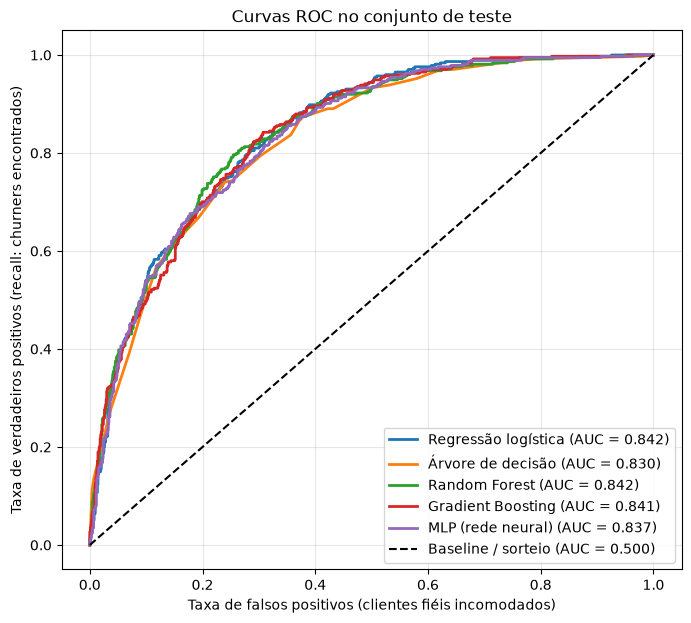

In [11]:
plt.figure(figsize=(8, 7))
for nome, pipe in pipelines.items():
    proba = pipe.predict_proba(X_teste)[:, 1]
    fpr, tpr, _ = roc_curve(y_teste, proba)
    plt.plot(fpr, tpr, linewidth=2, label=f'{nome} (AUC = {roc_auc_score(y_teste, proba):.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Baseline / sorteio (AUC = 0.500)')
plt.xlabel('Taxa de falsos positivos (clientes fiéis incomodados)')
plt.ylabel('Taxa de verdadeiros positivos (recall: churners encontrados)')
plt.title('Curvas ROC no conjunto de teste')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

As curvas dos melhores modelos praticamente se sobrepõem. Quando o desempenho empata, **o critério de escolha passa a ser outro**: custo, velocidade, facilidade de explicar a decisão e de manter o modelo em produção.

## 7. Do modelo à decisão: qual limiar usar?

O modelo devolve uma **probabilidade**. Quem decide a partir de qual probabilidade o cliente recebe a oferta é o **negócio**. Lembre do ato 3 da Demo 2: mexer no limiar troca precisão por recall.

Vamos colocar números (hipotéticos, mas plausíveis) na campanha:

- a oferta de retenção (desconto) custa **R$ 100** por cliente abordado;
- um cliente que cancela representa uma perda de **R$ 1.000** em receita futura;
- a oferta **convence 40%** dos clientes que iam cancelar a ficar.

Então, para cada cliente abordado:

- se ele **ia cancelar** (verdadeiro positivo): ganho esperado de $0,4 \times 1.000 - 100 = $ **R$ 300**;
- se ele **não ia cancelar** (falso positivo): perda de **R$ 100** (desconto dado a quem ficaria de qualquer jeito).

Limiar padrão (0.50)   = 0.50 | abordados:  318 | precisão: 0.66 | recall: 0.56 | resultado: R$    51.800
Limiar ótimo           = 0.26 | abordados:  590 | precisão: 0.51 | recall: 0.80 | resultado: R$    60.600
Abordar todo mundo            | abordados: 1409 | resultado: R$     8.700


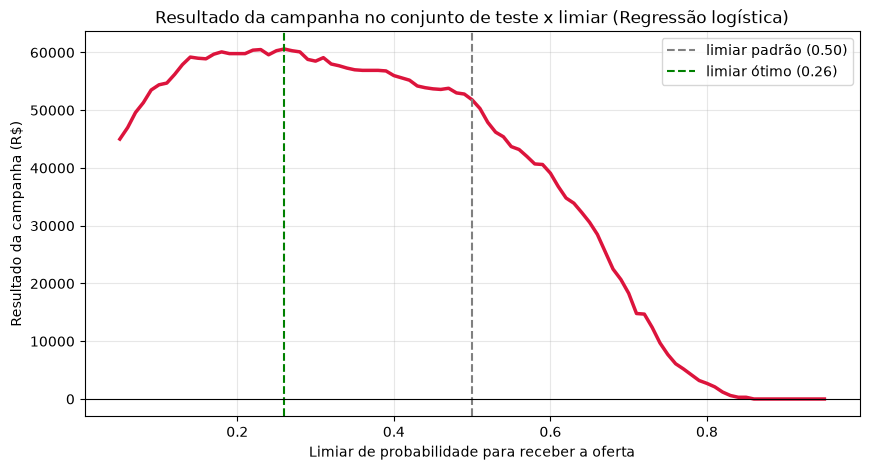

In [12]:
CUSTO_OFERTA = 100
VALOR_CLIENTE = 1000
TAXA_SUCESSO = 0.40

def resultado_campanha(y_real, proba, limiar):
    abordados = proba >= limiar
    vp = np.sum(abordados & (y_real == 1))
    fp = np.sum(abordados & (y_real == 0))
    return vp * (TAXA_SUCESSO * VALOR_CLIENTE - CUSTO_OFERTA) - fp * CUSTO_OFERTA, abordados.sum()

melhor_nome = tabela.index[0]
proba_melhor = pipelines[melhor_nome].predict_proba(X_teste)[:, 1]
y_real = y_teste.to_numpy()

limiares = np.linspace(0.05, 0.95, 91)
lucros = [resultado_campanha(y_real, proba_melhor, l)[0] for l in limiares]
limiar_otimo = limiares[int(np.argmax(lucros))]

for nome_cenario, limiar in [('Limiar padrão (0.50)', 0.5), ('Limiar ótimo', limiar_otimo)]:
    lucro, n_abordados = resultado_campanha(y_real, proba_melhor, limiar)
    pred = (proba_melhor >= limiar).astype(int)
    print(f'{nome_cenario:22s} = {limiar:.2f} | abordados: {n_abordados:4d} | '
          f'precisão: {precision_score(y_real, pred):.2f} | recall: {recall_score(y_real, pred):.2f} | '
          f'resultado: R$ {lucro:>9,.0f}'.replace(',', '.'))

todos = resultado_campanha(y_real, proba_melhor, 0.0)[0]
print(f'{"Abordar todo mundo":22s}        | abordados: {len(y_real):4d} | resultado: R$ {todos:>9,.0f}'.replace(',', '.'))

plt.figure(figsize=(10, 5))
plt.plot(limiares, lucros, color='crimson', linewidth=2.5)
plt.axvline(0.5, color='gray', linestyle='--', label='limiar padrão (0.50)')
plt.axvline(limiar_otimo, color='green', linestyle='--', label=f'limiar ótimo ({limiar_otimo:.2f})')
plt.axhline(0, color='black', linewidth=0.8)
plt.title(f'Resultado da campanha no conjunto de teste x limiar ({melhor_nome})')
plt.xlabel('Limiar de probabilidade para receber a oferta')
plt.ylabel('Resultado da campanha (R$)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**O limiar padrão de 0.5 não é sagrado.** Como errar para um lado (desconto desperdiçado, R$ 100) custa muito menos do que errar para o outro (cliente perdido), vale abordar clientes com probabilidade **bem abaixo de 50%**. O limiar ótimo sai da **conta do negócio**, não da estatística.

Experimente: mude `CUSTO_OFERTA` para 300 e rode de novo. O limiar ótimo sobe, porque cada oferta passa a ser mais cara.

## 8. O que o modelo aprendeu?

Um diretor vai perguntar: **"por que esse cliente está na lista?"**. Vamos usar a **importância por permutação**: embaralhamos uma variável de cada vez no teste e medimos o quanto a AUC cai. Se cair muito, o modelo depende daquela variável. A técnica funciona para **qualquer** modelo, inclusive o MLP.

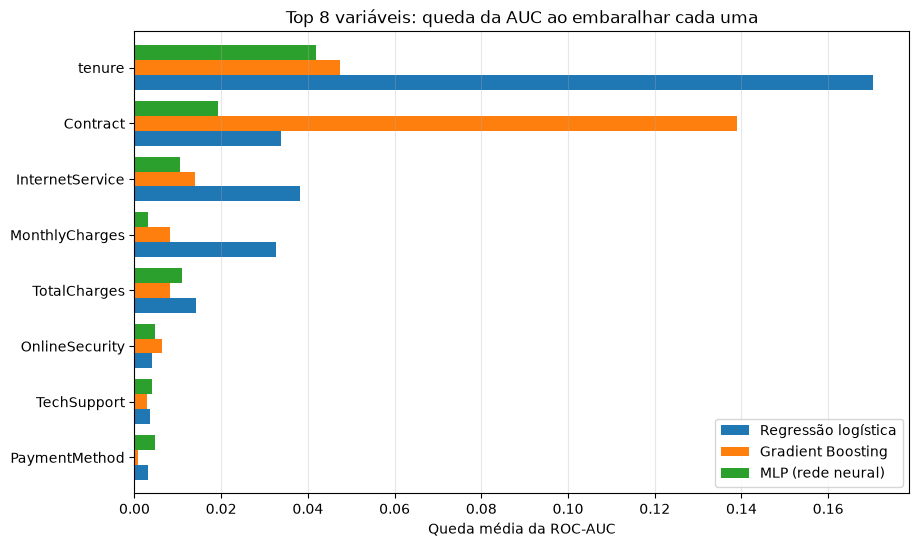

,Regressão logística,Gradient Boosting,MLP (rede neural)
tenure,0.1702,0.0474,0.0420
Contract,0.0338,0.1391,0.0194
InternetService,0.0381,0.0140,0.0106
MonthlyCharges,0.0326,0.0083,0.0032
TotalCharges,0.0142,0.0082,0.0110
OnlineSecurity,0.0041,0.0062,0.0048
TechSupport,0.0035,0.0029,0.0041
PaymentMethod,0.0031,0.0009,0.0048


In [13]:
def importancia(pipe, nome):
    r = permutation_importance(pipe, X_teste, y_teste, scoring='roc_auc',
                               n_repeats=10, random_state=SEMENTE, n_jobs=-1)
    return pd.Series(r.importances_mean, index=X_teste.columns, name=nome)

imp = pd.concat([importancia(pipelines['Regressão logística'], 'Regressão logística'),
                 importancia(pipelines[melhor_nome], melhor_nome) if melhor_nome != 'Regressão logística'
                 else importancia(pipelines['Gradient Boosting'], 'Gradient Boosting'),
                 importancia(pipelines['MLP (rede neural)'], 'MLP (rede neural)')], axis=1)
imp = imp.loc[imp.mean(axis=1).sort_values(ascending=False).index].head(8)

imp.iloc[::-1].plot(kind='barh', figsize=(10, 6), width=0.8)
plt.title('Top 8 variáveis: queda da AUC ao embaralhar cada uma')
plt.xlabel('Queda média da ROC-AUC')
plt.grid(alpha=0.3, axis='x')
plt.show()

imp.round(4)

Os modelos, por caminhos matemáticos completamente diferentes, chegam a **conclusões parecidas**: **tempo de casa** (`tenure`) e **tipo de contrato** aparecem entre os três fatores mais importantes nos três modelos. Os pesos variam porque as duas variáveis contam quase a mesma história (cliente novo costuma estar no contrato mensal), e cada modelo distribui o crédito de um jeito. Bate com o gráfico da seção 2, o que dá confiança de que o modelo aprendeu algo real e não um vazamento como o da Demo 2.

A diferença está **no quanto é fácil explicar**:

- na **regressão logística**, cada coeficiente tem leitura direta ("contrato mensal aumenta o risco em X vezes");
- nos **ensembles de árvores**, há boas ferramentas de explicação, mas a lógica é menos direta;
- no **MLP**, os pesos das camadas ocultas não têm leitura humana; dependemos inteiramente de técnicas externas como a permutação.

Em setores regulados (crédito, seguros, saúde), essa diferença pode decidir sozinha qual modelo vai para produção.

## 9. Conclusão: e então, ML clássico ou rede neural?

| Critério | ML clássico (linear, árvores, ensembles) | Redes neurais |
| --- | --- | --- |
| Tipo de dado | **Tabular** (planilhas, bancos de dados, CRM) | **Não estruturado** (imagem, texto, áudio, vídeo) |
| Volume de dados | Funciona bem com milhares de linhas | Brilha com volumes muito grandes |
| Variáveis | Exige bom *feature engineering* | Aprende as representações sozinha |
| Interpretabilidade | Alta (linear) a média (ensembles) | Baixa; depende de técnicas externas |
| Custo de treino e operação | Baixo, roda em CPU | Médio a alto, muitas vezes exige GPU |
| Neste case | **Empate técnico com o MLP, com mais simplicidade** | Sem ganho que justifique a complexidade |

**A lição de fechamento da disciplina:** não existe modelo campeão universal. Existe o modelo **adequado ao dado, à pergunta de negócio e às restrições de operação**. Comece sempre pelo baseline e pelo modelo mais simples; suba a complexidade só quando o ganho pagar o custo.

E quando o dado deixa de ser uma planilha e passa a ser **pixels, palavras e sequências**? Aí as redes neurais mudam de patamar, e é exatamente por aí que começa a próxima disciplina: **Deep Learning and Modern Neural Architectures**.